In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/jigsaw-toxic-comment-classification-challenge/train.csv.zip
/kaggle/input/jigsaw-toxic-comment-classification-challenge/sample_submission.csv.zip
/kaggle/input/jigsaw-toxic-comment-classification-challenge/test_labels.csv.zip
/kaggle/input/jigsaw-toxic-comment-classification-challenge/test.csv.zip


# Introduction to Multilabel Classification

Multilabel classification is a type of classification problem where each instance (data point) can be assigned multiple labels simultaneously. Unlike traditional classification tasks where each instance is associated with a single label, multilabel classification allows for a more flexible and nuanced understanding of the data. This is particularly useful in scenarios where data points can belong to multiple categories at once.

For example, in the context of toxic comment classification, a single comment might be labeled as both "toxic" and "insulting," or "obscene" and "threatening." The goal is to build a model that can accurately predict all applicable labels for each comment.

# Step 1: Import Libraries and Load Dataset

In [3]:
%%capture
!pip install itables

from itables import init_notebook_mode, show
init_notebook_mode(all_interactive=False,connected=True)

In [4]:
# Set Seed for reproducibility
seed = 42

# Exploratory Data Analysis (EDA)

Before diving into model building, it's essential to understand the data. We'll start by loading the dataset and examining the distribution of the target labels to check for any imbalance.

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


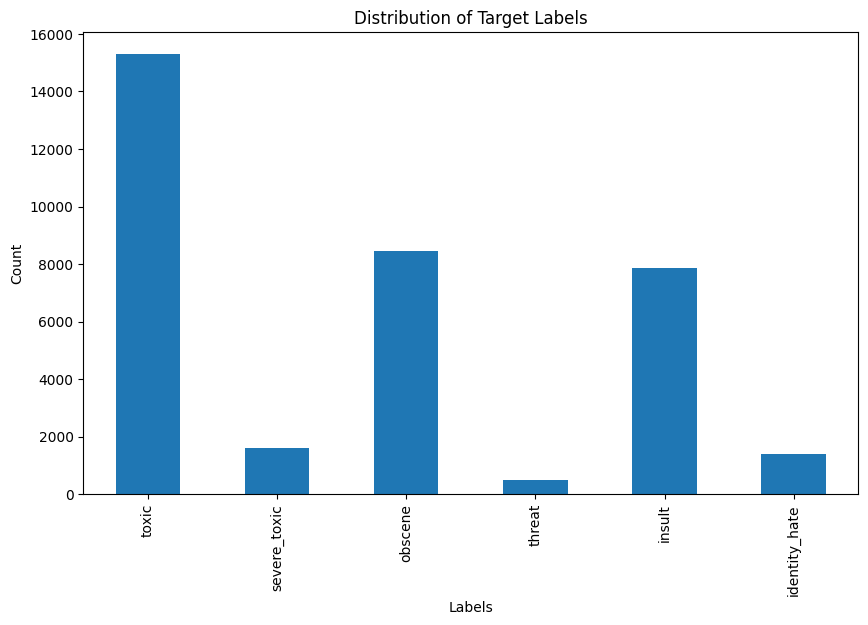

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pd.set_option('display.max_colwidth', None)

# Reading CSV file from ZIP archive
df_full_train = pd.read_csv('/kaggle/input/jigsaw-toxic-comment-classification-challenge/train.csv.zip', compression='zip')
df_full_test = pd.read_csv('/kaggle/input/jigsaw-toxic-comment-classification-challenge/test.csv.zip', compression='zip')

# Define the target columns
labels_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Check for missing values
print(df_full_train.isnull().sum())

# Plot the distribution of the target labels
plt.figure(figsize=(10,6))
df_full_train[labels_cols].sum().plot(kind='bar')
plt.title('Distribution of Target Labels')
plt.xlabel('Labels')
plt.ylabel('Count')
plt.show()

## Checking for Correlations Between Labels
Understanding the correlations between labels can provide valuable insights into the relationships between different types of toxicity. For example, a comment labeled as "toxic" might also be likely to be labeled as "insulting" or "obscene." Identifying these correlations can help us understand the data better and potentially improve our model's performance by leveraging these relationships.

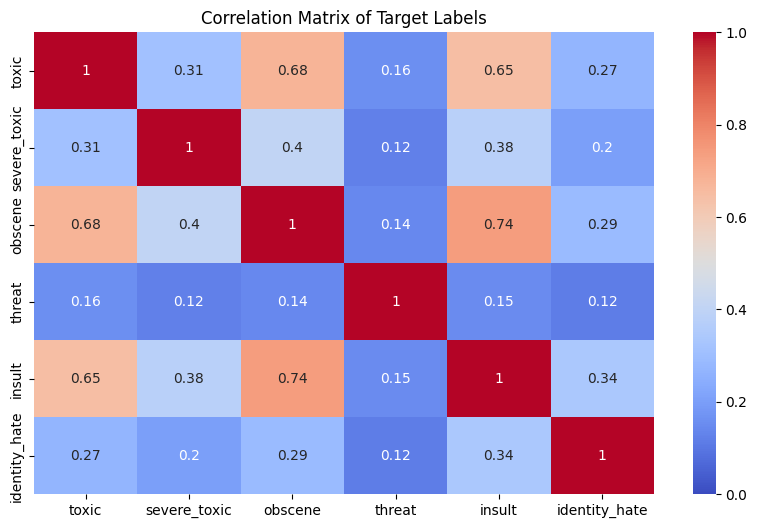

In [6]:
# Calculate the correlation matrix
correlation_matrix = df_full_train[labels_cols].corr()

# Plot the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Correlation Matrix of Target Labels')
plt.show()

**Why Checking for Correlations is Important**

1. Understanding Relationships: Correlations can reveal how different types of toxicity are related. For example, if "toxic" and "insult" have a high correlation, it suggests that comments labeled as "toxic" are often also labeled as "insulting.
2. Feature Engineering: Knowing the correlations can help in feature engineering. For instance, if certain labels are highly correlated, we might create new features that capture these relationships.
3. Model Performance: Leveraging correlations can improve model performance. If the model understands that certain labels often appear together, it can make more accurate predictions.
4. Data Imbalance: Correlations can also highlight issues with data imbalance. If certain labels are rarely correlated with others, it might indicate that those labels are underrepresented in the dataset.

In this instance, we observe a correlation between the labels 'toxic', 'obscene', and 'insult'. This indicates that the labels are not independent. Recognizing label dependencies is crucial for selecting an appropriate problem transformation strategy for model training. While binary relevance is suitable for scenarios where labels are independent, it is often advantageous to employ problem transformation strategies that account for label correlations, such as classifier chains and label powerset, as we will discuss further.

## Checking for Imbalance with the "None" Label
To understand the imbalance between comments with no toxic labels and those with toxic labels, we'll add a "none" column and visualize its distribution separately.

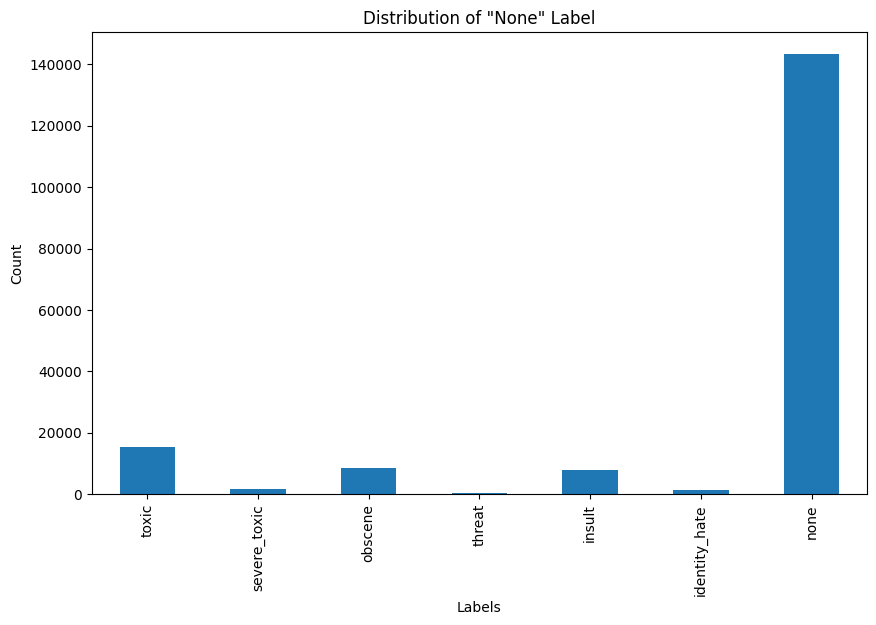

In [7]:
# Add a column to check for comments with no toxic labels
df_full_train['none'] = 1 - df_full_train[labels_cols].max(axis=1)

# Plot the distribution of the "none" label
plt.figure(figsize=(10,6))
df_full_train[labels_cols+['none']].sum().plot(kind='bar')
plt.title('Distribution of "None" Label')
plt.xlabel('Labels')
plt.ylabel('Count')
plt.show()

# Section 1: Traditional Machine Learning Models

---

**Introduction to Traditional Machine Learning Methods**

Traditional machine learning (ML) methods have been the backbone of many classification tasks for years. These methods are well-established, easy to implement, and often provide strong baseline performance. In the context of multilabel classification, several traditional ML methods can be employed to predict multiple labels for each instance. Here are some of the most commonly used and useful classifier models:

#### Commonly Used Classifier Models

1. **Logistic Regression**:
   - **Description**: Logistic Regression is a linear model used for binary claClassifier`.
   - **Handling Imbalance**: Logistic Regression can handle class imbalance using the `class_weight` parameter. Setting `class_weight='balanced'` adjusts the weights inversely proportional to class f
ultaneously.

2. **Multinomial Naive Bayes**:
   - **Description**: Multinomial Naive Bayes is a probabilistic classifier based on Bayes' theorem. It is particularly effective for text classification tasks.
   - **Handling Imbalance**: Multinomial Naive Bayes does not have built-in mechanisms to handle class imbalance. Manual resampling techniques, such as oversampling the minority class or undersampling the majority clas
   s simultaneously.

3. **Support Vector Machines (SVM)**:
   - **Description**: SVM is a powerful classifier that finds the hyperplane that best separates the classes. It can be extended to multilabel classification using techniques like One-vs-Rest (OvR).
   - **Handling Imbalance**: SVM can handle class imbalance using the `class_weight` parameter. Setting `class_weight='balanced'` adjusts the weights inversely proportional 
   labels simultaneously.

4. **Random Forest**:
   - **Description**: Random Forest is an ensemble method that combines multiple decision trees to improve classification performance. It is robust to overfitting and can handle high-dimensional data.
   - **Handling Imbalance**: Random Forest can handle class imbalance using the `class_weight` parameter. Setting `class_weight='balanced'` adjusts the weights inversely proporti
   iple labels simultaneously.

5. **Gradient Boosting Machines (GBM)**:
   - **Description**: GBM is an ensemble method that builds models sequentially, with each new model correcting the errors of the previous ones. It is highly effective for classification tasks.
   - **Handling Imbalance**: GBM does not have built-in mechanisms to handle class imbalance. Manual resampling techniques or adjusting the `scale_pos_weight` parameter in specific implementat
    multiple labels simultaneously.

### Approaches to Multilabel Classification

Multilabel classification involves predicting multiple labels for each instance. There are several approaches to tackle this problem, each with its own advantages and disadvantages. Here are the main approaches:

#### 1. Problem Transformation Methods

Problem transformation methods convert the multilabel classification problem into multiple single-label classification problems. The most common techniques are:

1. **Binary Relevance (BR)**:
   - **How it works**: Treats each label as a separate binary classification problem. For example, if there are six labels, it trains six independent classifiers.
   - **Advantages**: Simple to implement and understand. Each label is treated independently, which can be beneficial if the labels are not strongly correlated.
   - **Disadvantages**: Does not leverage potential correlations between labels. Can be computationally expensive if the number of labels is large.

2. **Label Powerset (LP)**:
   - **How it works**: Treats each unique combination of labels as a single label in a multiclass classification problem. For example, if there are three labels, the possible combinations are treated as distinct classes.
   - **Advantages**: Leverages correlations between labels by considering label combinations. Can be more efficient if the number of unique label combinations is small.
   - **Disadvantages**: Can lead to a large number of classes if the number of unique label combinations is high. May suffer from class imbalance if some label combinations are rare.

3. **Classifier Chains (CC)**:
   - **How it works**: Trains a sequence of binary classifiers, where each classifier deals with one label and takes into account the predictions of previous classifiers in the chain.
   - **Advantages**: Leverages correlations between labels by considering the predictions of previous classifiers. Can improve performance compared to Binary Relevance.
   - **Disadvantages**: The order of classifiers in the chain can affect performance. More complex to implement and understand compared to Binary Relevance.

#### 2. Algorithm Adaptation Methods

Algorithm adaptation methods modify existing algorithms to handle multilabel classification directly. These methods are often more complex but can be more effective in leveraging label correlations. Some common techniques include:

1. **Multilabel k-Nearest Neighbors (ML-kNN)**:
   - **How it works**: Extends the k-Nearest Neighbors algorithm to handle multilabel classification by considering the labels of the k-nearest neighbors.
   - **Advantages**: Simple to implement and understand. Can leverage label correlations by considering the labels of neighboring instances.
   - **Disadvantages**: Can be computationally expensive for large datasets. Performance depends on the choice of k and distance metric.

2. **Multilabel Decision Trees**:
   - **How it works**: Extends decision tree algorithms to handle multilabel classification by considering multiple labels at each split.
   - **Advantages**: Can handle complex interactions between labels and features. Can be used as a base classifier in ensemble methods like Random Forest.
   - **Disadvantages**: Can be prone to overfitting. More complex to implement compared to single-label decision trees.

3. **Multilabel Neural Networks**:
   - **How it works**: Extends neural network architectures to handle multilabel classification by using multiple output neurons, each corresponding to a label.
   - **Advantages**: Can handle complex interactions between labels and features. Can leverage deep learning techniques for feature extraction and representation learning.
   - **Disadvantages**: Requires more computational resources and training data. More complex to implement and tune compared to traditional ML methods.

### Summary

- **Problem Transformation Methods**: Convert the multilabel problem into multiple single-label problems. Examples include Binary Relevance, Label Powerset, and Classifier Chains.
- **Algorithm Adaptation Methods**: Modify existing algorithms to handle multilabel classification directly. Examples include Multilabel k-Nearest Neighbors, Multilabel Decision Trees, and Multilabel Neural Networks.

## Light Text Cleaning
Before training the models, we'll perform some light text cleaning to remove unwanted characters and normalize the text.

In [8]:
import re
import string

def clean_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'\[.*?\]', '', text)  # Remove text in square brackets
    text = re.sub(r'https?://\S+|www\.\S+', '', text)  # Remove URLs
    text = re.sub(r'<.*?>+', '', text)  # Remove HTML tags
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)  # Remove punctuation
    text = re.sub(r'\n', '', text)  # Remove newline characters
    text = re.sub(r'\w*\d\w*', '', text)  # Remove words containing numbers
    return text

# Apply the cleaning function to the comment_text column
df_full_train['comment_text'] = df_full_train['comment_text'].apply(clean_text)
df_full_test['comment_text'] = df_full_test['comment_text'].apply(clean_text)
show(df_full_train)

### Applying Different Multilabel Classification Strategies and Classifiers

---

In this section, we'll explore various strategies and classifiers for handling multilabel classification problems. We'll implement different strategies such as `MultiOutputClassifier`, `BinaryRelevance`, `ClassifierChain`, and `LabelPowerset` using classifiers like Logistic Regression, SVM, and Random Forest. We'll also use `make_pipeline` from `sklearn` to create a pipeline that includes both the TF-IDF vectorization and the selected model.

**Note**: In this section, data imbalance is addressed by using internal parameters (`class_weight='balanced'`) in the classifiers.

#### Step-by-Step Implementation

1. **TF-IDF Vectorization**: Convert the text data into numerical features using `TfidfVectorizer`.
2. **Classifier Selection**: Choose between Logistic Regression, SVM, and Random Forest with `class_weight='balanced'` to handle class imbalance.
3. **Strategy Selection**: Choose between different multilabel classification strategies: `MultiOutputClassifier`, `BinaryRelevance`, `ClassifierChain`, and `LabelPowerset`.
   - **MultiOutputClassifier** and **BinaryRelevance**: Both treat each label as a separate binary classification problem and train independent classifiers for each label. They essentially perform the same function but are implemented in different libraries.
4. **Pipeline**: Use `make_pipeline` to create a pipeline that includes both the TF-IDF vectorization and the selected model.
5. **Training and Evaluation**: Train the model on the training data and evaluate it on the testing data.

In [9]:
# Randomly downsample to 50,000 elements 
df_full_train[labels_cols].sum()

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64

In [10]:
df_full_train['none'].sum()

143346

In [11]:
from skmultilearn.problem_transform import BinaryRelevance, ClassifierChain, LabelPowerset
from sklearn.multioutput import MultiOutputClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, hamming_loss, roc_auc_score
from sklearn.model_selection import train_test_split

# Define the target columns
labels_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Split the dataset into features and target variables
X = df_full_train['comment_text']
y = df_full_train[labels_cols]

# Split the dataset into training and testing sets
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.33, random_state=seed)

def build_model(strategy='multioutput', classifier='logistic'):
    
    # Select the classifier
    if classifier == 'logistic': 
        base_classifier = LogisticRegression(random_state=seed, class_weight='balanced') 
    elif classifier == 'svm': 
        base_classifier = SVC(random_state=seed, class_weight='balanced', probability=True) 
    elif classifier == 'randomforest': 
        base_classifier = RandomForestClassifier(random_state=seed, class_weight='balanced') 
    else: 
        raise ValueError("Invalid classifier. Choose from 'logistic', 'svm', 'randomforest'.")

    # Select the strategy
    if strategy == 'multioutput':
        model = MultiOutputClassifier(base_classifier) 
    elif strategy == 'binaryrelevance':
        model = BinaryRelevance(base_classifier) # same thing as MultiOutputClassifier
    elif strategy == 'classifierchain':
        model = ClassifierChain(base_classifier)
    elif strategy == 'labelpowerset':
        model = LabelPowerset(base_classifier)
    else:
        raise ValueError("Invalid strategy. Choose from 'multioutput', 'binaryrelevance', 'classifierchain', 'labelpowerset'.")
    
    # Instantiate tfidf vectorizer
    tfidf = TfidfVectorizer(max_features=None, stop_words='english', min_df=10, max_df=0.95) # used max_features=5000 for classifier chain because it threw memory errors
    
    # Create a pipeline with TF-IDF vectorizer and the model
    pipeline = make_pipeline(tfidf, model)
    
    # Train the model
    pipeline.fit(X_train, y_train)
    
    # Predict and evaluate
    y_pred = pipeline.predict(X_valid)
    
    # Calculate and print accuracy
    accuracy = accuracy_score(y_valid, y_pred)
    print(f'Accuracy: {round(accuracy, 2)}')
    
    # Detailed classification report
    print("-"*50)
    print(f"Classification Report:\n", classification_report(y_valid, y_pred, target_names=labels_cols))
    
    # Calculate and print Hamming Loss
    hamming = hamming_loss(y_valid, y_pred)
    print(f'Hamming Loss: {hamming}')
    
    # # Calculate and print AUC-ROC for each label and take the average
    # auc_roc = roc_auc_score(y_valid, y_pred, average='macro')
    # print(f'AUC-ROC: {auc_roc}')

    return pipeline, accuracy, hamming

In [ ]:
# IF PROBLEMS WITH LABELPOWERSET
# https://github.com/scikit-learn/scikit-learn/issues/28565
# !pip install scikit-learn==1.2.2

strategy = 'classifierchain'
classifier = 'logistic'

pipe, accuracy, hamming = build_model(strategy=strategy, classifier=classifier)

predictions = pipe.predict(df_full_test['comment_text']).toarray()

# Ensure the shape of predictions matches the number of columns in labels_cols
print(predictions.shape)
print(len(labels_cols))

# Create a DataFrame with the predictions
submission_df = pd.DataFrame(predictions, columns=labels_cols)

# Add the 'id' column from the test DataFrame
submission_df['id'] = df_full_test['id']

# Reorder columns to have 'id' first
submission_df = submission_df[['id'] + labels_cols]

# Display the submission DataFrame
display(submission_df.head())

# Save the submission DataFrame to a CSV file
submission_df.to_csv(f'sub_toxic_comment_classification_{strategy}+{classifier}.csv', index=False)

# tdifd MAX_FEATURES=5000
# SCORE classifierchain + logistic: .892
# SCORE binaryrelevance/multioutput + logistic: .891
# SCORE labelpowerset + logistic: .793
# SCORE multioutput + randomforest: .679

# tdifd MAX_FEATURES=NONE
# SCORE binaryrelevance/multioutput + logistic: .899

In [ ]:
# BRUTEFORCE SEARCH
classifiers = ['logistic', 'svm', 'randomforest']
strategies = ['binaryrelevance', 'classifierchain', 'labelpowerset']

# Initialize an empty list to store results
results = []

for classifier in classifiers:
    for strategy in strategies:
        # Build the model and get accuracy and hamming loss
        pipe, accuracy, hamming = build_model(strategy=strategy, classifier=classifier)
        
        # Append the results to the list
        results.append({'strategy': strategy, 'classifier': classifier, 'accuracy': accuracy, 'hamming_loss': hamming})

# Convert the results list to a pandas DataFrame
results_df = pd.DataFrame(results)

# Display the DataFrame
results_df

### Handling Class Imbalance with XGBoost and Multinomial Naive Bayes

---

In this section, we'll explore how to handle class imbalance for models like XGBoost and Multinomial Naive Bayes, which don't have the same internal parameters as Logistic Regression, SVM, and Random Forest. For XGBoost, we'll use a dynamic `scale_pos_weight`, and for Multinomial Naive Bayes, we'll use manual resampling techniques such as Random Under Sampler.

#### Step-by-Step Implementation

1. **TF-IDF Vectorization**: Convert the text data into numerical features using `TfidfVectorizer`.
2. **XGBoost**: Use a dynamic `scale_pos_weight` to handle class imbalance.
3. **Multinomial Naive Bayes**: Use manual resampling techniques like Random Under Sampler to handle class imbalance.
4. **Pipeline**: Use `make_pipeline` to create a pipeline that includes both the TF-IDF vectorization and the selected model.
5. **Training and Evaluation**: Train the model on the training data and evaluate it on the testing data.

### Implementing XGBoost with Dynamic `scale_pos_weight`

In [36]:
from xgboost import XGBClassifier
from tqdm import tqdm

# Specify Cols
labels_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Initialize an empty DataFrame to store predictions
predictions_df = pd.DataFrame()

# Add the 'id' column from the test DataFrame
predictions_df['id'] = df_full_test['id']

for label in tqdm(labels_cols):
    print("="*50,f"Processing {label}","="*50)
    # Split the dataset into features and target variables
    X = df_full_train['comment_text']
    y = df_full_train[label]

    # Split the dataset into training and testing sets
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.33, random_state=seed)

    # Instantiate tfidf vectorizer
    tfidf = TfidfVectorizer(max_features=None, stop_words='english', min_df=10, max_df=0.95)

    # Calculate scale_pos_weight for the current label
    pos_weight = (y_train==0).sum() / (y_train==1).sum()
    
    # Create instance of the XGBoost classifier
    xgb = XGBClassifier(random_state=seed,scale_pos_weight=pos_weight)

    # Create a pipeline with TF-IDF vectorizer and the model
    pipeline = make_pipeline(tfidf, xgb)

    # Train the model with sample weights
    pipeline.fit(X_train, y_train)

    # Predict and evaluate (valid set)
    y_pred = pipeline.predict(X_valid)

    # Calculate and print accuracy
    accuracy = accuracy_score(y_valid, y_pred)
    print(f'Accuracy: {round(accuracy, 2)}')

    # Detailed classification report
    print("-"*50)
    print(f"Classification Report:\n", classification_report(y_valid, y_pred))

    # Calculate and print Hamming Loss
    # hamming = hamming_loss(y_valid, y_pred)
    # print(f'Hamming Loss: {hamming}')

    # Calculate and print AUC-ROC for each label and take the average
    # auc_roc = roc_auc_score(y_test, y_pred, average='macro')
    # print(f'AUC-ROC: {auc_roc}')
    
    # Predict (test set)
    predictions_df[label] = pipeline.predict(df_full_test['comment_text']) 

# Display the DataFrame
print(predictions_df.shape)
show(predictions_df)

# Save the DataFrame to a CSV file
predictions_df.to_csv("sub_toxic_comment_classification_binaryrelevance+xgb.csv",index=False)

# SCORE: .88

(153164, 7)


* SCORE binaryrelevance + XGB: .88892

### Implementing Multinomial Naive Bayes with Random Under Sampler

In [25]:
import imblearn
from imblearn.under_sampling import RandomUnderSampler
from sklearn.naive_bayes import MultinomialNB

# Split the dataset into features and target variables
X = df_full_train['comment_text']
y = df_full_train[labels_cols]

# Initialize an empty DataFrame to store predictions
predictions_df = pd.DataFrame()

# Add the 'id' column from the test DataFrame
predictions_df['id'] = df_full_test['id']

# Split the dataset into training and testing sets
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.33, random_state=seed)

# Creating instances of the classifiers
tfidf = TfidfVectorizer(max_features=None, stop_words='english', min_df=10, max_df=0.95)
rus = RandomUnderSampler(sampling_strategy=1, random_state=seed)
mnb = MultinomialNB()

pipeline = imblearn.pipeline.Pipeline([
            ('tfidf', tfidf),
            ('undersample', rus),
            ('classifier', mnb),
        ])

for label in tqdm(labels_cols):
    print("="*50,f"Processing {label}","="*50)
    loop_y = y_train[label]

    # train the model
    pipeline.fit(X_train, loop_y)
    
    # Predict and evaluate (valid set)
    y_pred = pipeline.predict(X_valid)

    # Calculate and print accuracy
    accuracy = accuracy_score(y_valid[label], y_pred)
    print(f'Accuracy: {round(accuracy, 2)}')

    # Detailed classification report
    print("-"*50)
    print(f"Classification Report:\n", classification_report(y_valid[label], y_pred))
   
    # Predict (test set)
    predictions_df[label] = pipeline.predict(df_full_test['comment_text']) 

# Display the DataFrame
print(predictions_df.shape)
show(predictions_df)

# Save the DataFrame to a CSV file
predictions_df.to_csv("sub_toxic_comment_classification_binaryrelevance+mnb.csv",index=False)

# SCORE: .887

  0%|          | 0/6 [00:00<?, ?it/s]

================================================== Processing toxic ==================================================
Accuracy: 0.88
--------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.87      0.93     47576
           1       0.43      0.89      0.58      5083

    accuracy                           0.88     52659
   macro avg       0.71      0.88      0.75     52659
weighted avg       0.93      0.88      0.89     52659



 17%|█▋        | 1/6 [00:16<01:21, 16.33s/it]

================================================== Processing severe_toxic ==================================================
Accuracy: 0.91
--------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.91      0.95     52133
           1       0.10      0.96      0.18       526

    accuracy                           0.91     52659
   macro avg       0.55      0.93      0.56     52659
weighted avg       0.99      0.91      0.94     52659



 33%|███▎      | 2/6 [00:32<01:04, 16.12s/it]

================================================== Processing obscene ==================================================
Accuracy: 0.89
--------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.89      0.94     49828
           1       0.31      0.91      0.47      2831

    accuracy                           0.89     52659
   macro avg       0.65      0.90      0.70     52659
weighted avg       0.96      0.89      0.91     52659



... (4 outputs left out)

 83%|████████▎ | 5/6 [01:19<00:15, 15.86s/it]

================================================== Processing identity_hate ==================================================
Accuracy: 0.87
--------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.87      0.93     52188
           1       0.06      0.94      0.12       471

    accuracy                           0.87     52659
   macro avg       0.53      0.91      0.52     52659
weighted avg       0.99      0.87      0.92     52659



100%|██████████| 6/6 [01:35<00:00, 15.95s/it]

(153164, 7)


### Explanation

1. **TF-IDF Vectorization**: Convert the text data into numerical features using `TfidfVectorizer`.
2. **XGBoost**: Use a dynamic `scale_pos_weight` to handle class imbalance. This adjusts the weight of the positive class based on the imbalance in the training data.
3. **Multinomial Naive Bayes**: Use manual resampling techniques like Random Under Sampler to handle class imbalance. This technique randomly undersamples the majority class to balance the dataset.
4. **Pipeline**: Use `make_pipeline` to create a pipeline that includes both the TF-IDF vectorization and the selected model.
5. **Training and Evaluation**: Train the model on the training data and evaluate it on the testing data. Calculate and print accuracy, Hamming Loss, and AUC-ROC for a comprehensive evaluation.

# Section 2: Advanced Models Using Neural Networks
In this section, we'll explore more advanced models using neural networks. We'll start with common approaches and then move on to using BERT for text classification.

## Step 1: Common Neural Network Approaches
We'll use a simple neural network model for text classification.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, GlobalAveragePooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenize and pad the text data
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(X_train_seq, maxlen=200, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=200, padding='post', truncating='post')

# Define the neural network model
model = Sequential([
    Embedding(5000, 64, input_length=200),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(6, activation='sigmoid')
])

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_pad, y_train, epochs=5, batch_size=32, validation_data=(X_test_pad, y_test))

# Evaluate the model
loss, accuracy = model.evaluate(X_test_pad, y_test)
print(f'Accuracy: {round(accuracy, 2)}')


In [ ]:
# Tokenize and pad the new text data
new_texts_seq = tokenizer.texts_to_sequences(df_full_train['comment_text'])
new_texts_pad = pad_sequences(new_texts_seq, maxlen=200, padding='post', truncating='post')

# Make predictions
predictions = model.predict(new_texts_pad)

# Print the predictions
print(predictions)


In [ ]:
predictions

## Step 2: Using BERT for Text Classification

In [ ]:
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch

# Load the BERT tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Tokenize and pad the text data
X_train_enc = tokenizer(X_train.tolist(), truncation=True, padding=True, max_length=200, return_tensors='pt')
X_test_enc = tokenizer(X_test.tolist(), truncation=True, padding=True, max_length=200, return_tensors='pt')

# Define the BERT model
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=6)

# Define training arguments
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=10,
)

# Create Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=torch.utils.data.TensorDataset(X_train_enc['input_ids'], torch.tensor(y_train.values)),
    eval_dataset=torch.utils.data.TensorDataset(X_test_enc['input_ids'], torch.tensor(y_test.values)),
)

# Train the model
trainer.train()

# Evaluate the model
results = trainer.evaluate()
print(f"Accuracy: {results['eval_accuracy']}")


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Load dataset
df = pd.read_csv('/kaggle/input/jigsaw-toxic-comment-classification-challenge/train.csv.zip')

# Dataset overview
print(df.info())
print(df.head())

# Check for missing values
print(f"Missing values:\n{df.isnull().sum()}")

# Target labels
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Label distribution
label_counts = df[label_cols].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='viridis')
plt.title("Label Distribution")
plt.ylabel("Count")
plt.xlabel("Toxic Labels")
plt.show()

# Co-occurrence of labels
cooccurrence = df[label_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(cooccurrence, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Label Co-occurrence Matrix")
plt.show()

# Comment length distribution
df['comment_length'] = df['comment_text'].apply(lambda x: len(x.split()))
plt.figure(figsize=(12, 6))
sns.histplot(df['comment_length'], bins=50, kde=True, color='blue')
plt.title("Comment Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# WordCloud for toxic vs non-toxic comments
toxic_comments = " ".join(df[df['toxic'] == 1]['comment_text'])
nontoxic_comments = " ".join(df[df['toxic'] == 0]['comment_text'])

wordcloud_toxic = WordCloud(width=800, height=400, background_color='black').generate(toxic_comments)
wordcloud_nontoxic = WordCloud(width=800, height=400, background_color='white').generate(nontoxic_comments)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud for Toxic Comments")

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_nontoxic, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud for Non-Toxic Comments")
plt.show()


In [ ]:
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, Dense, GlobalMaxPool1D, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import numpy as np

from keras.prepro

# Preprocessing
max_words = 20000
max_len = 100
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(df['comment_text'])

X = tokenizer.texts_to_sequences(df['comment_text'])
X = pad_sequences(X, maxlen=max_len)

y = df[label_cols].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=seed)

# Model
model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=max_len),
    GlobalMaxPool1D(),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(len(label_cols), activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, batch_size=32, epochs=3, validation_split=0.1)

# Evaluate model
y_pred = model.predict(X_test)
roc_auc_scores = [roc_auc_score(y_test[:, i], y_pred[:, i]) for i in range(len(label_cols))]
print(f"ROC-AUC Scores: {roc_auc_scores}")
